# 03 · Forecasting monthly collisions

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryam843/uk-road-accident-analytics/blob/main/notebooks/03_forecasting.ipynb)

**Series:** reported road collisions per month, GB, 2005-01 to 2019-12 (180 months, no gaps,
month-start frequency).

**Splits (locked):** training 2005-01..2016-12; test 2017-01..2019-12. The test period is used once,
at the end.

**Models**
| Model | What it does |
|---|---|
| Seasonal naive | next January = last January, and so on. The simplest baseline. |
| Trend x seasonal profile | a straight line fitted to the annual totals of the training years, extended to each forecast year, times the mean share of each month in the last 3 training years (`src/evaluate.py`). A second, stronger baseline. |
| ETS | Holt-Winters exponential smoothing: additive damped trend, multiplicative seasonality (statsmodels). |
| SARIMA | `auto_arima` (pmdarima) chooses the order **once, on the training data**. The order is then fixed and reported, and only its coefficients are re-estimated at each origin. |

**Evaluation**
1. Rolling-origin backtest inside the training period: origins every 12 months from 2012-12
   (2012-12, 2013-12, 2014-12, 2015-12), horizon 12. Each fit sees only data up to its origin.
2. Final test: fit on 2005-01..2016-12, forecast 2017-01..2019-12 (36 months).
3. Replica check: fit on 2005-01..2014-12, forecast the 2015 annual total. Compared with the
   official RAS0101 figure and with seasonal naive.
4. Residual diagnostics for SARIMA (Ljung-Box, ACF).

Caveat: the SARIMA order is chosen with data up to 2016-12, so the earlier backtest origins
benefit slightly from an order chosen with later data. Coefficients are still re-fitted using
data up to each origin only.

**Results (this run):** no model wins everywhere. On the 2017-2019 test, the trend x seasonal
profile baseline has the lowest error (MAE 482.14, MAPE 4.60%), ahead of SARIMA(1,1,1)x(1,0,2,12)
(MAE 529.39, MAPE 5.26%), ETS (602.34) and seasonal naive (1,107.72). SARIMA forecasts too many
collisions in 31 of 36 test months. On the 2013-2016 backtest SARIMA has the lowest error (474.34)
and the trend baseline the highest (998.84). In the 2015 replica check ETS is closest to the
official total. SARIMA residuals still show autocorrelation (Ljung-Box p 0.000 at lag 12), and its
80% and 95% intervals contain 35 and 36 of the 36 test months.

In [1]:
# Setup: works from the repo root, from notebooks/, or on Google Colab.
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src/config.py").exists():
    if not Path("uk-road-accident-analytics").exists():
        !git clone -q https://github.com/maryam843/uk-road-accident-analytics.git
    %cd uk-road-accident-analytics
    %pip install -q -r requirements.txt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import logging

import matplotlib.pyplot as plt
import pandas as pd

from src import clean, config, evaluate

config.setup_logging(logging.INFO)
evaluate.apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

DATA_DIR = config.get_data_dir()
RAW, PROCESSED = DATA_DIR / "raw", DATA_DIR / "processed"
if not (PROCESSED / config.COLLISIONS_PARQUET).exists():
    # Fresh runtime (e.g. Colab): download (several GB) and clean. Takes a while, once.
    from src import download

    download.main([])
    clean.run()
print("DATA_DIR =", config.display_path(DATA_DIR))

DATA_DIR = data


In [3]:
import warnings

import numpy as np
import pmdarima as pm
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

monthly = pd.read_parquet(PROCESSED / config.MONTHLY_PARQUET)["collisions"].astype(float)
monthly.index = pd.DatetimeIndex(monthly.index, freq="MS")
assert len(monthly) == 180 and monthly.index.freqstr == "MS" and monthly.notna().all()
assert (monthly > 0).all(), "a month with zero collisions would make MAPE undefined"

train = monthly.loc[:config.FORECAST_TRAIN_END]
test = monthly.loc[config.FORECAST_TEST_START:config.FORECAST_TEST_END]
print(f"train: {train.index[0]:%Y-%m}..{train.index[-1]:%Y-%m} ({len(train)} months); "
      f"test: {test.index[0]:%Y-%m}..{test.index[-1]:%Y-%m} ({len(test)} months)")

train: 2005-01..2016-12 (144 months); test: 2017-01..2019-12 (36 months)


23:14:47 INFO src.evaluate: Saved figure reports/figures/03_monthly_series.png


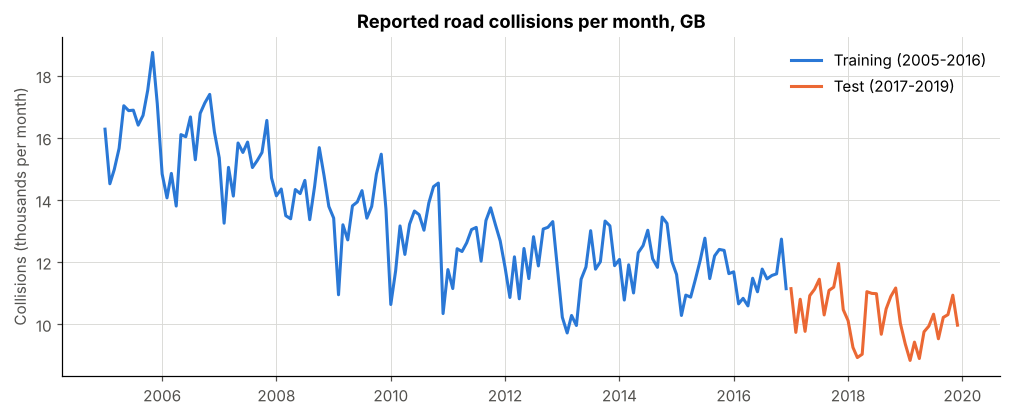

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(train.index, train / 1000, label="Training (2005-2016)")
ax.plot(test.index, test / 1000, label="Test (2017-2019)")
ax.set_title("Reported road collisions per month, GB")
ax.set_ylabel("Collisions (thousands per month)")
ax.legend()
evaluate.save_fig(fig, "03_monthly_series")
plt.show()

## Choose the SARIMA order on the training data

In [5]:
auto = pm.auto_arima(train, seasonal=True, m=12, stepwise=True, information_criterion="aic",
                     suppress_warnings=True, error_action="ignore", random_state=config.RANDOM_STATE)
ORDER, SEASONAL_ORDER, WITH_INTERCEPT = auto.order, auto.seasonal_order, auto.with_intercept
print(f"Chosen on 2005-01..2016-12: SARIMA{ORDER}x{SEASONAL_ORDER}, intercept={WITH_INTERCEPT}, "
      f"AIC={auto.aic():,.1f}")
print(f"auto_arima chose this order once, on all of {train.index[0]:%Y-%m}..{train.index[-1]:%Y-%m}. "
      f"The same order is used at every backtest origin (from {config.BACKTEST_FIRST_ORIGIN}), "
      "so the backtest errors are slightly optimistic.")

Chosen on 2005-01..2016-12: SARIMA(1, 1, 1)x(1, 0, 2, 12), intercept=False, AIC=2,330.5
auto_arima chose this order once, on all of 2005-01..2016-12. The same order is used at every backtest origin (from 2012-12), so the backtest errors are slightly optimistic.


In [6]:
def fc_seasonal_naive(y, h):
    return evaluate.seasonal_naive(y, h).to_numpy()


def fc_ets(y, h):
    fit = ExponentialSmoothing(y, trend="add", damped_trend=True, seasonal="mul",
                               seasonal_periods=12, initialization_method="estimated").fit()
    return np.asarray(fit.forecast(h))


def fc_trend_season(y, h):
    return evaluate.trend_seasonal_profile(y, h).to_numpy()


def fit_sarima(y):
    return pm.ARIMA(order=ORDER, seasonal_order=SEASONAL_ORDER, with_intercept=WITH_INTERCEPT,
                    suppress_warnings=True).fit(y)


def fc_sarima(y, h):
    return np.asarray(fit_sarima(y).predict(n_periods=h))


MODELS = {"Seasonal naive": fc_seasonal_naive, "ETS": fc_ets, "SARIMA": fc_sarima,
          "Trend x seasonal profile": fc_trend_season}

## Rolling-origin backtest (inside the training period)

In [7]:
origins = list(pd.date_range(config.BACKTEST_FIRST_ORIGIN, train.index[-1] - pd.DateOffset(months=12),
                             freq="12MS"))
print("origins:", [f"{o:%Y-%m}" for o in origins])
backtest = evaluate.rolling_origin_backtest(train, origins, config.BACKTEST_HORIZON, MODELS)
per_origin = backtest.groupby(["origin", "model"]).apply(
    lambda g: evaluate.mae(g["actual"], g["forecast"]), include_groups=False).unstack("model")
print("MAE per origin (collisions per month):")
display(per_origin.style.format("{:,.0f}"))

origins: ['2012-12', '2013-12', '2014-12', '2015-12']


MAE per origin (collisions per month):


model,ETS,SARIMA,Seasonal naive,Trend x seasonal profile
origin,,,,
2012-12-01 00:00:00,567,723,721,656
2013-12-01 00:00:00,964,456,668,"1,472"
2014-12-01 00:00:00,287,373,584,984
2015-12-01 00:00:00,330,346,430,883


## Final test: 2017-01..2019-12

In [8]:
test_fc = pd.DataFrame({name: fn(train, len(test)) for name, fn in MODELS.items()}, index=test.index)
metrics = pd.concat(
    {
        "Backtest 2013-2016 (4 origins × 12 months)": evaluate.summarise_forecasts(backtest),
        "Test 2017-2019 (36 months)": pd.DataFrame(
            {m: evaluate.forecast_metrics(test, test_fc[m]) for m in MODELS}).T,
    },
    axis=1,
)
display(metrics.style.format("{:,.2f}"))

## Error per test year

Trend x seasonal profile: a straight line fitted to the 2005-2016 annual totals, extended to
each test year, times the mean 2014-2016 share of each month. Mean error is forecast minus
actual, so a positive value means the model forecast too many collisions.

In [9]:
rows = []
for name in MODELS:
    for year in (2017, 2018, 2019):
        m = test.index.year == year
        rows.append({"model": name, "year": year, "MAE": evaluate.mae(test[m], test_fc[name][m]),
                     "MAPE_%": evaluate.mape(test[m], test_fc[name][m]),
                     "mean_error": float(np.mean(test_fc[name][m] - test[m]))})
per_year = pd.DataFrame(rows).set_index(["model", "year"])
display(per_year.style.format({"MAE": "{:,.2f}", "MAPE_%": "{:.2f}", "mean_error": "{:+,.2f}"}))

sarima_error = test_fc["SARIMA"] - test
print("SARIMA mean error per month (forecast minus actual): "
      + ", ".join(f"{y} {sarima_error[test.index.year == y].mean():+,.0f}" for y in (2017, 2018, 2019))
      + f". It over-forecasts in {int((sarima_error > 0).sum())} of {len(test)} test months.")

SARIMA mean error per month (forecast minus actual): 2017 +234, 2018 +533, 2019 +661. It over-forecasts in 31 of 36 test months.


23:15:20 INFO src.evaluate: Saved figure reports/figures/03_test_forecasts.png


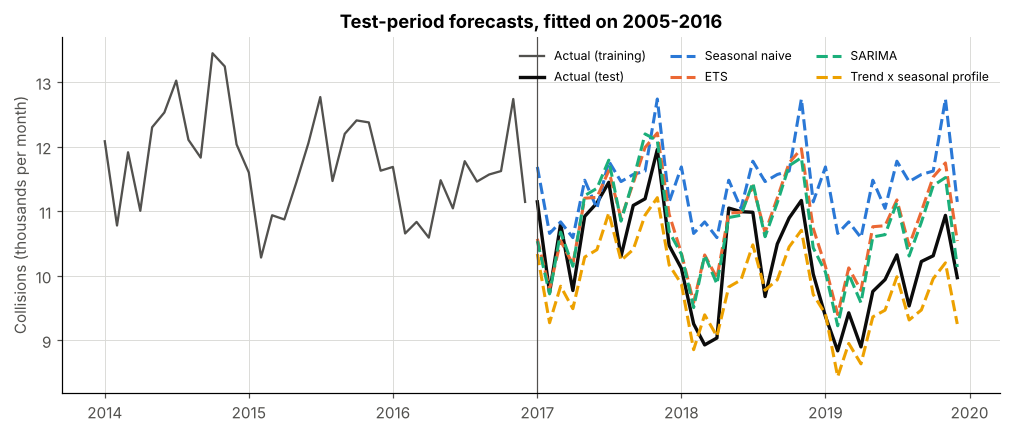

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.2))
history = monthly.loc["2014-01":config.FORECAST_TRAIN_END]
ax.plot(history.index, history / 1000, color="#52514e", linewidth=1.5, label="Actual (training)")
ax.plot(test.index, test / 1000, color="#0b0b0b", linewidth=2.2, label="Actual (test)")
for name in MODELS:
    ax.plot(test.index, test_fc[name] / 1000, linestyle="--", label=name)
ax.axvline(test.index[0], color="#52514e", linewidth=0.8)
ax.set_title("Test-period forecasts, fitted on 2005-2016")
ax.set_ylabel("Collisions (thousands per month)")
ax.legend(ncols=3, fontsize=8)
evaluate.save_fig(fig, "03_test_forecasts")
plt.show()

## Replica check: forecast the 2015 total from data up to 2014

In [11]:
train_2014 = monthly.loc[:"2014-12"]
actual_2015 = monthly.loc["2015"].sum()
official = clean.load_ras0101(RAW / config.RAS0101_RAW_FILE)
official_2015 = float(official.loc[2015, "collisions"])
replica = pd.DataFrame({name: {"forecast_2015_total": fn(train_2014, 12).sum()} for name, fn in MODELS.items()}).T
replica["pipeline_actual_2015"] = actual_2015
replica["ras0101_official_2015"] = official_2015
replica["error_vs_official"] = replica["forecast_2015_total"] - official_2015
replica["pct_error_vs_official"] = 100 * replica["error_vs_official"] / official_2015
display(replica.style.format("{:,.1f}"))

,forecast_2015_total,pipeline_actual_2015,ras0101_official_2015,error_vs_official,pct_error_vs_official
Seasonal naive,"146,322.0","140,056.0","140,056.0","6,266.0",4.5
ETS,"141,958.8","140,056.0","140,056.0","1,902.8",1.4
SARIMA,"143,466.9","140,056.0","140,056.0","3,410.9",2.4
Trend x seasonal profile,"128,245.2","140,056.0","140,056.0","-11,810.8",-8.4


## SARIMA residual diagnostics (fit on 2005-2016)

,lb_stat,lb_pvalue
12,27.78,0.000
24,41.02,0.002


Ljung-Box H0: residuals are uncorrelated up to the given lag; a small p-value means structure is left in the residuals.


23:15:22 INFO src.evaluate: Saved figure reports/figures/03_sarima_residuals.png


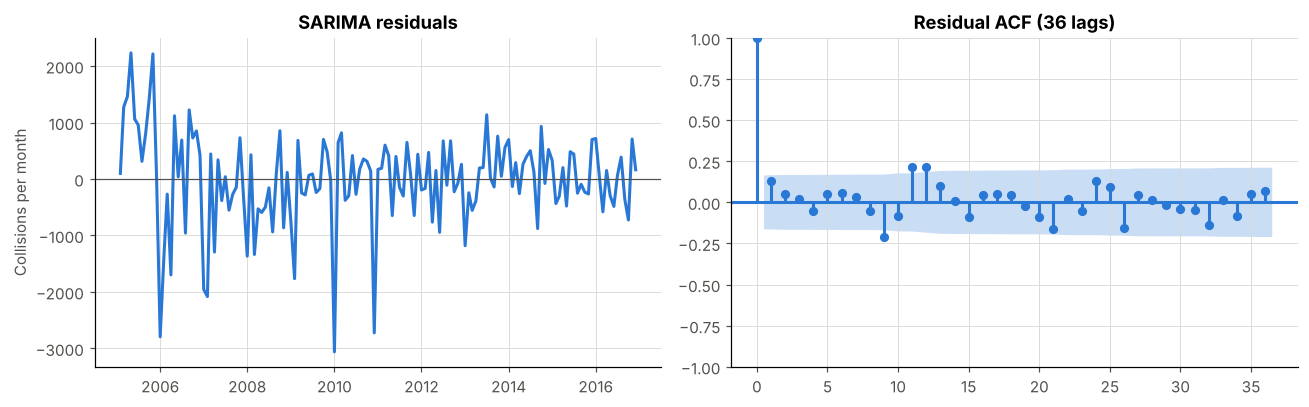

In [12]:
sarima_train = fit_sarima(train)
burn_in = ORDER[1] + 12 * SEASONAL_ORDER[1]
resid = pd.Series(sarima_train.resid(), index=train.index).iloc[burn_in:]
n_params = ORDER[0] + ORDER[2] + SEASONAL_ORDER[0] + SEASONAL_ORDER[2]
lb = acorr_ljungbox(resid, lags=[12, 24], model_df=n_params)
display(lb.style.format({"lb_stat": "{:.2f}", "lb_pvalue": "{:.3f}"}))
print("Ljung-Box H0: residuals are uncorrelated up to the given lag; "
      "a small p-value means structure is left in the residuals.")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(resid.index, resid)
axes[0].axhline(0, color="#52514e", linewidth=0.8)
axes[0].set_title("SARIMA residuals")
axes[0].set_ylabel("Collisions per month")
plot_acf(resid, lags=36, ax=axes[1], title="Residual ACF (36 lags)")
fig.tight_layout()
evaluate.save_fig(fig, "03_sarima_residuals")
plt.show()

## Verdict

In [13]:
for period in metrics.columns.levels[0]:
    mae_naive = metrics.loc["Seasonal naive", (period, "MAE")]
    mae_sarima = metrics.loc["SARIMA", (period, "MAE")]
    best = metrics[(period, "MAE")].idxmin()
    if mae_sarima < mae_naive:
        verdict = f"SARIMA beats seasonal naive (MAE {mae_sarima:,.0f} vs {mae_naive:,.0f})"
    else:
        verdict = (f"SARIMA does NOT beat seasonal naive (MAE {mae_sarima:,.0f} vs "
                   f"{mae_naive:,.0f}); the simpler baseline is at least as good")
    print(f"{period}: {verdict}. Lowest MAE: {best}.")

Backtest 2013-2016 (4 origins × 12 months): SARIMA beats seasonal naive (MAE 474 vs 601). Lowest MAE: SARIMA.
Test 2017-2019 (36 months): SARIMA beats seasonal naive (MAE 529 vs 1,108). Lowest MAE: Trend x seasonal profile.


**Interpretation:**
- **No model wins everywhere.** On the 2017-2019 test the trend x seasonal profile baseline has
  the lowest MAE (482.14, MAPE 4.60%), then SARIMA (529.39, MAPE 5.26%), ETS (602.34, MAPE 6.01%)
  and seasonal naive (1,107.72, MAPE 11.17%). On the 2013-2016 backtest SARIMA is best (474.34)
  and the trend baseline is worst (998.84), because a straight line fitted from 2005 extends the
  steep 2005-2010 fall.
- **SARIMA beats seasonal naive** on both periods, but it forecasts too high in every test year
  (mean error +234, +533 and +661 collisions per month in 2017, 2018 and 2019; 31 of 36 months
  too high), because collisions kept falling. The trend baseline forecasts too low in every test
  year. Seasonal naive does worst on the test because it repeats 2016 for three years.
- **2015 replica:** fitted on data to 2014, ETS was closest to the official 2015 total (error
  +1.4%), then SARIMA (+2.4%), seasonal naive (+4.5%) and the trend baseline (-8.4%); percentages
  as printed, 1 decimal. So the best model depends on the horizon and the period.
- **Limitation:** the Ljung-Box test rejects "no autocorrelation" in the SARIMA residuals
  (p 0.000 at lag 12, 0.002 at lag 24). Some structure is left unmodelled.

Notes for reading the numbers:
- Monthly counts are not adjusted for the number of days in a month. All models see the same
  series, so the comparison is fair, but part of the "seasonality" is calendar length.
- A forecast of reported collisions inherits any change in police reporting practice. The
  severity reporting change affects severity, not the all-collision count used here.

## Added evaluation: SARIMA prediction-interval coverage on 2017-2019

The SARIMA model fitted on 2005-2016 (the same fit as the residual diagnostics above) gives 80%
and 95% prediction intervals for the 36 test months. Empirical coverage is the share of test
months whose actual count falls inside the interval. If the intervals were well calibrated,
about 80% and 95% of months would be inside. The Ljung-Box result above (autocorrelation left
in the residuals) suggests they may be too narrow.

,months_inside,months,empirical_coverage,months_below,months_above,mean_width,coverage_2017,coverage_2018,coverage_2019
nominal_level,,,,,,,,,
0.800000,35,36,0.972,1,0,"2,644",1.000,0.917,1.000
0.950000,36,36,1.000,0,0,"4,043",1.000,1.000,1.000


23:15:23 INFO src.evaluate: Saved figure reports/figures/03_sarima_interval_coverage.png


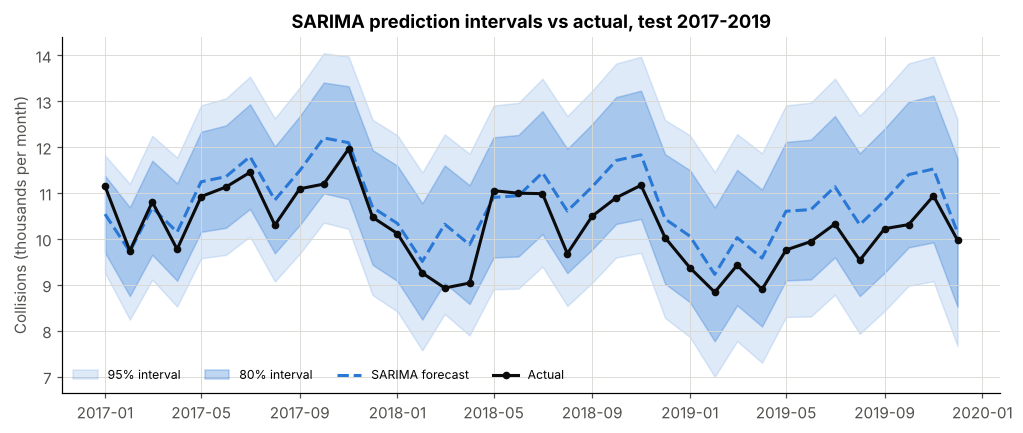

In [14]:
cover_rows, bands = [], {}
for level in (0.80, 0.95):
    point, ci = sarima_train.predict(n_periods=len(test), return_conf_int=True, alpha=1 - level)
    point = np.asarray(point)
    assert np.allclose(point, test_fc["SARIMA"]), "same model as the test forecast"
    lo, hi = ci[:, 0], ci[:, 1]
    bands[level] = (lo, hi)
    actual = test.to_numpy()
    inside = (actual >= lo) & (actual <= hi)
    cover_rows.append({"nominal_level": level, "months_inside": int(inside.sum()), "months": len(test),
                       "empirical_coverage": inside.mean(), "months_below": int((actual < lo).sum()),
                       "months_above": int((actual > hi).sum()), "mean_width": float(np.mean(hi - lo))})
    for year in (2017, 2018, 2019):
        m = test.index.year == year
        cover_rows[-1][f"coverage_{year}"] = inside[m].mean()
coverage = pd.DataFrame(cover_rows).set_index("nominal_level")
display(coverage.style.format({"empirical_coverage": "{:.3f}", "mean_width": "{:,.0f}", "coverage_2017": "{:.3f}",
                               "coverage_2018": "{:.3f}", "coverage_2019": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.fill_between(test.index, bands[0.95][0] / 1000, bands[0.95][1] / 1000, color=evaluate.PALETTE[0], alpha=0.15,
                label="95% interval")
ax.fill_between(test.index, bands[0.80][0] / 1000, bands[0.80][1] / 1000, color=evaluate.PALETTE[0], alpha=0.3,
                label="80% interval")
ax.plot(test.index, test_fc["SARIMA"] / 1000, color=evaluate.PALETTE[0], linestyle="--", label="SARIMA forecast")
ax.plot(test.index, test / 1000, color="#0b0b0b", marker="o", markersize=4, label="Actual")
ax.set_title("SARIMA prediction intervals vs actual, test 2017-2019")
ax.set_ylabel("Collisions (thousands per month)")
ax.legend(ncols=4, fontsize=8)
evaluate.save_fig(fig, "03_sarima_interval_coverage")
plt.show()

**Result: the intervals are wide, not too narrow.** 35 of the 36 test months (0.972) fall
inside the 80% interval and all 36 (1.000) inside the 95% interval. The single miss is below
the 80% band, in 2018. Mean widths are 2,644 and 4,043 collisions per month. The model is
differenced (d = 1), so its intervals widen quickly with the horizon, and over three years that
outweighs the leftover autocorrelation. With 36 months each month is 1/36 of the coverage, so
this is a coarse check.
Practical reading: the trend x seasonal profile baseline gives the lowest test error but no
interval. SARIMA's point forecast runs high on this test period, but its intervals are
conservative and contained every test month at the 95% level.